**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**02 | Signal Preprocessing: Windowing and Quality Controls**

![Signal preprocessing and windowing workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/02_workflow.svg)

**Objective:** Segment continuous HARTH accelerometer recordings into two-second, label-pure windows, excluding candidates that cross activity changes or timestamp discontinuities.

**Dataset:** The pinned HARTH v2.0 recording `S023.csv`, with lower-back and thigh acceleration sampled at 50 Hz.

**Notebook Scope:** Generate windows for one participant, inspect retained activity support and signal segments, and verify window integrity. No fitted scaling, model training or subject-independent evaluation is performed.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ---------------------------- 1. Standard Library ----------------------------
import sys
from pathlib import Path

# --------------------- 2. Repository Path Configuration ----------------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside human-movement-intelligence.")
    root = root.parent
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ----------------------- 5. Shared and Study Utilities -----------------------
from core.data_inspection import inspect_data, plot_signal
from core.signal_preprocessing import create_signal_windows
from harth_data import ACTIVITY_NAMES, ensure_harth_sample, load_harth_subject

# -------------------- 6. Output Directory and Setup Summary ------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Windowing function:", create_signal_windows.__name__)
print("Research output directory:", output_dir)

Windowing function: create_signal_windows
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Load the Original HARTH Recording**

The source file is retrieved from the pinned public release or reused from the local Git-ignored cache.

In [3]:
# ===================== 02. Load Original HARTH Recording =====================
data_dir = root / "data" / "raw" / "harth_v2"
file_path = ensure_harth_sample(data_dir, subject="S023")
data, channels = load_harth_subject(file_path)
inspect_data(data, name="HARTH S023: continuous input")

print("Participant:", file_path.stem)
print("Recorded activity classes:", sorted(data["label"].unique().tolist()))


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S023.csv
HARTH subject S023: 137,646 rows, 6 sensors

===== HARTH S023: continuous input =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Participant: S023
Recorded activity classes: [1, 2, 3, 4, 5, 6, 7, 8]


**03. Define the Windowing Protocol**

At 50 Hz, each 100-sample window spans two seconds. A 50-sample stride creates 50% overlap between candidates. Retained windows must contain a single activity label and no non-positive or excessive timestamp intervals (greater than 1.5 times the expected interval).

In [4]:
# ======================= 03. Define Windowing Protocol =======================
SAMPLING_RATE = 50
WINDOW_SECONDS = 2.0
OVERLAP = 0.5
WINDOW_SIZE = int(WINDOW_SECONDS * SAMPLING_RATE)
STEP_SIZE = int(WINDOW_SIZE * (1 - OVERLAP))
print(f"Sampling rate: {SAMPLING_RATE} Hz")
print(f"Window length: {WINDOW_SIZE} samples ({WINDOW_SECONDS:.1f} seconds)")
print(f"Step: {STEP_SIZE} samples | Overlap: {OVERLAP:.0%}")


Sampling rate: 50 Hz
Window length: 100 samples (2.0 seconds)
Step: 50 samples | Overlap: 50%


**04. Generate Label-Pure Signal Windows**

`X_windows` is organised as `(windows, channels, time)`, with corresponding class labels in `y_windows`. The `window_info` table records participant identity and original source indices. No scaling or model fitting is performed.

In [5]:
# ================== 04. Generate Label-Pure Signal Windows ===================

# ----------------- 1. Source Signals and Label-Pure Windows ------------------
signals = data[channels].to_numpy()
labels = data["label"].to_numpy()
X_windows, y_windows, window_info = create_signal_windows(
    signals=signals,
    labels=labels,
    window_size=WINDOW_SIZE,
    step_size=STEP_SIZE,
    timestamps=data["timestamp"],  # Check source timing continuity.
    sampling_rate=SAMPLING_RATE,
    min_label_purity=1.0,  # Exclude mixed-activity windows.
    subject_id=file_path.stem,
)

# ------------------ 2. Window Shapes and Source Provenance -------------------
print("Window tensor X:", X_windows.shape)
print("Window target y:", y_windows.shape)
print("First retained windows:")
display(window_info.head(8))


Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Window tensor X: (2567, 6, 100)
Window target y: (2567,)
First retained windows:


,subject_id,start_index,end_index_exclusive,label,label_purity
0,S023,0,100,6,1.0
1,S023,50,150,6,1.0
2,S023,100,200,6,1.0
3,S023,150,250,6,1.0
4,S023,200,300,6,1.0
5,S023,350,450,1,1.0
6,S023,400,500,1,1.0
7,S023,450,550,1,1.0


**05. Inspect Retained Activity Support**

Compare annotated source samples with retained windows for each activity. Windows that cross label changes or timestamp discontinuities are excluded, so the class proportions may differ from those in the original recording.

,activity,source_samples,retained_windows
0,Walking,70601,1352
1,Running,22391,441
2,Shuffling,2071,7
3,Stairs ascending,3194,42
4,Stairs descending,2291,26
5,Standing,7455,114
6,Sitting,13059,257
7,Lying,16584,328


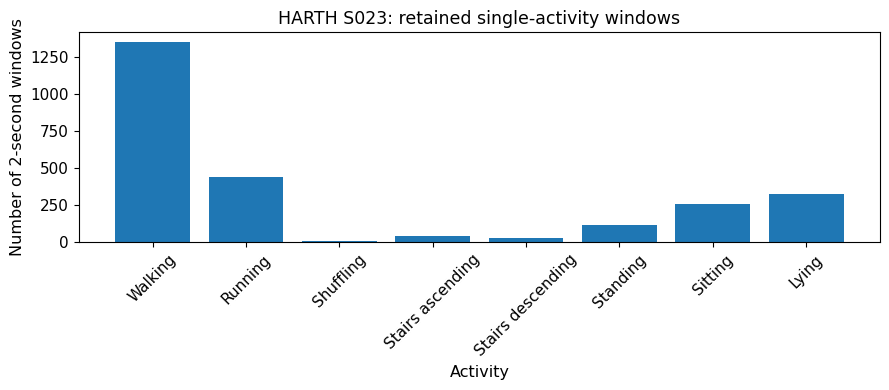

In [6]:
# =================== 05. Inspect Retained Activity Support ===================

# ------------------ 1. Source and Retained Activity Counts -------------------
original_counts = data["label"].value_counts().sort_index()
window_counts = pd.Series(y_windows, name="label").value_counts().sort_index()
distribution = pd.DataFrame({
    "activity": [ACTIVITY_NAMES[int(code)] for code in original_counts.index],
    "source_samples": original_counts.to_numpy(),
    "retained_windows": [
        int(window_counts.get(code, 0)) for code in original_counts.index
    ],
})
display(distribution)
distribution.to_csv(output_dir / "02_window_activity_support.csv", index=False)

# --------------------- 2. Activity Support Visualisation ---------------------
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(distribution["activity"], distribution["retained_windows"])
ax.set(
    title="HARTH S023: retained single-activity windows",
    xlabel="Activity", ylabel="Number of 2-second windows",
)
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
save_figure(fig, output_dir / "02_retained_activity_distribution.png")
plt.show()


**06. Visualise an Original Signal Window**

Plot the lower-back acceleration channels from the first retained two-second window, using the original values in **g** without filtering or scaling.

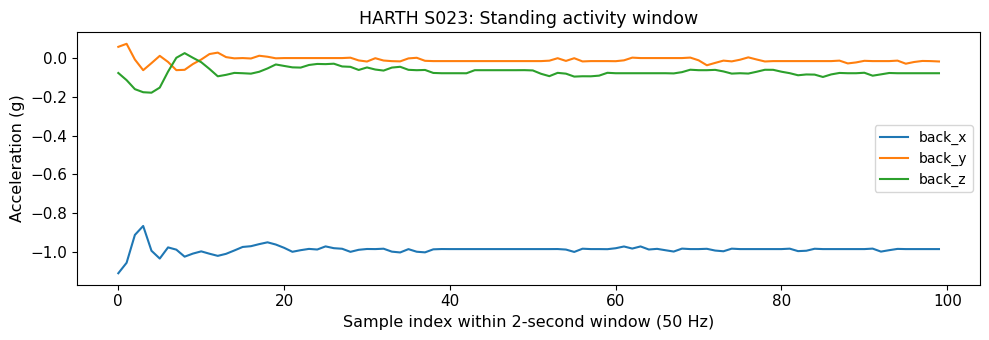

Source indices: 0 to 99
Label purity: 1.0


In [7]:
# =================== 06. Visualise Original Window Signals ===================

# ------------------ 1. Select and Visualise a Source Window ------------------
if len(X_windows) == 0:
    raise RuntimeError("No eligible windows; check source labels and timestamps.")

first_window = 0
activity_code = int(y_windows[first_window])
fig = plot_signal(
    X_windows[first_window, :3, :],
    title=f"HARTH S023: {ACTIVITY_NAMES[activity_code]} activity window",
    channel_names=channels[:3],
)
fig.axes[0].set_xlabel("Sample index within 2-second window (50 Hz)")
fig.axes[0].set_ylabel("Acceleration (g)")
save_figure(fig, output_dir / "02_example_window_signals.png")
plt.show()

# -------------------- 2. Window Indices and Label Purity ---------------------
print("Source indices:",
      int(window_info.iloc[first_window]["start_index"]), "to",
      int(window_info.iloc[first_window]["end_index_exclusive"]) - 1)
print("Label purity:", window_info.iloc[first_window]["label_purity"])


**07. Windowing Quality Gate**

The checks confirm tensor dimensions, source-index alignment, single-activity windows and participant identity. Overlapping windows from one participant do not support an unseen-participant performance claim.


In [8]:
# ======================== 07. Windowing Quality Gate =========================

# ---------------- 1. Check Window Integrity and Source Labels ----------------
assert X_windows.ndim == 3
assert X_windows.shape[1:] == (len(channels), WINDOW_SIZE)
assert len(X_windows) == len(y_windows) == len(window_info)
assert (window_info["label_purity"] == 1.0).all()
assert window_info["subject_id"].nunique() == 1
for row in window_info.itertuples(index=False):
    source_labels = labels[row.start_index:row.end_index_exclusive]
    assert len(source_labels) == WINDOW_SIZE
    assert (source_labels == row.label).all()

# -------------------------- 2. Quality Gate Summary --------------------------
print("Window shape and source-label agreement: PASSED")
print("Subject-independent validation: NOT POSSIBLE WITH ONE PARTICIPANT")
print("Feature scaling/training completed: NO")
print("Next: evaluate preprocessing/features and a full multi-subject split.")

# ----------------------- 3. Export Verified Windowing Evidence --------------
window_info.to_csv(output_dir / "02_window_metadata.csv", index=False)
windowing_summary = pd.DataFrame([{
    "subject_id": file_path.stem,
    "sampling_rate_hz": SAMPLING_RATE,
    "window_size_samples": WINDOW_SIZE,
    "step_size_samples": STEP_SIZE,
    "overlap_fraction": OVERLAP,
    "label_purity_threshold": 1.0,
    "source_rows": len(data),
    "retained_windows": len(X_windows),
    "signal_channels": len(channels),
}])
windowing_summary.to_csv(output_dir / "02_windowing_summary.csv", index=False)
# Retain the full numeric tensor locally for later analysis without re-windowing.
# Binary NPZ artefacts are excluded by the repository's current .gitignore.
np.savez_compressed(
    output_dir / "02_label_pure_windows.npz",
    X_windows=X_windows,
    y_windows=y_windows,
    channel_names=np.asarray(channels),
    window_size=np.int64(WINDOW_SIZE),
    step_size=np.int64(STEP_SIZE),
)
print("Reusable windowing evidence saved in:", output_dir)


Window shape and source-label agreement: PASSED
Subject-independent validation: NOT POSSIBLE WITH ONE PARTICIPANT
Feature scaling/training completed: NO
Next: evaluate preprocessing/features and a full multi-subject split.
Reusable windowing evidence saved in: /content/human-movement-intelligence/wearable_activity_recognition/output
